# Trabajo Práctico 1: Análisis descriptivo y predicción de informalidad
PE1333 Big Data, Maestría en Economía - UdeSA 2026. Grupo 9.



## Parte I: Analizando la base

### Inciso 1

In [1]:
# pandas maneja tablas de datos (DataFrames); numpy hace cálculo numérico
# y aporta np.nan, la marca de "dato faltante".
# "as pd" y "as np" son abreviaturas convencionales para escribir menos.
import numpy as np
import pandas as pd
from scipy import stats            # tests estadísticos (diferencia de medias)
import statsmodels.api as sm                          # logit con errores estándar; agrega la constante
from sklearn.model_selection import train_test_split   # partición en entrenamiento y test
import os                          # para crear carpetas donde guardar figuras y tablas
import matplotlib.pyplot as plt    # gráficos
import seaborn as sns              # gráficos estadísticos (incluye heatmap)

In [2]:
# Leemos las dos bases tal como las publica INDEC, sin limpiar.
# La ruta "data/..." es relativa a la carpeta TP1: por eso abrimos esa carpeta en VS Code.
individual = pd.read_excel("data/usu_individual_T126.xlsx")
hogar = pd.read_excel("data/usu_hogar_T126.xlsx")

# .shape devuelve (cantidad de filas, cantidad de columnas)
print("Individual:", individual.shape)
print("Hogar:", hogar.shape)

Individual: (43739, 234)
Hogar: (15447, 98)


In [3]:
# ESTADO es la condición de actividad (Diseño de registro, p. 18):
# 0 = entrevista no realizada, 1 = ocupado, 2 = desocupado, 3 = inactivo, 4 = menor de 10 años.
# value_counts() cuenta cuántas veces aparece cada valor; sort_index() los ordena por código.
individual["ESTADO"].value_counts().sort_index()

ESTADO
0       86
1    19573
2     1423
3    17983
4     4674
Name: count, dtype: int64

In [4]:
# individual["ESTADO"] == 1 produce una columna de True/False (True si la persona está ocupada).
# Poner esa columna entre corchetes deja sólo las filas con True.
# .copy() crea una tabla independiente: sin él, pandas podría tratar "ocupados" como una vista
# de "individual" y dar advertencias al modificarla.
ocupados = individual[individual["ESTADO"] == 1].copy()
print("Ocupados:", ocupados.shape)

Ocupados: (19573, 234)


In [5]:
# EMPLEO (Diseño de registro, p. 18): 1 = formal, 2 = informal, 9 = Ns/Nr.
print(ocupados["EMPLEO"].value_counts().sort_index())

# Dejamos afuera 9, nos quedamos sólo con 1 y 2.
ocupados = ocupados[ocupados["EMPLEO"].isin([1, 2])].copy()

# Recodificamos a 0/1. (ocupados["EMPLEO"] == 2) da True/False; .astype(int) convierte
# True en 1 y False en 0. Los modelos estiman Pr(Y = 1 | X), así que el 1 tiene que ser
# el evento que queremos predecir: ser informal.
ocupados["informal"] = (ocupados["EMPLEO"] == 2).astype(int)

print("\nObservaciones finales:", len(ocupados))
print(ocupados["informal"].value_counts())
print("Proporción de informales:", round(ocupados["informal"].mean(), 4))

EMPLEO
1.0    10762
2.0     8798
9.0       13
Name: count, dtype: int64

Observaciones finales: 19560
informal
0    10762
1     8798
Name: count, dtype: int64
Proporción de informales: 0.4498


Nos quedamos con los ocupados (ESTADO = 1, 19.573 personas) y construimos la variable
dependiente `informal` a partir de EMPLEO (1 si EMPLEO = 2, 0 si EMPLEO = 1), descartando
las 13 observaciones con código 9 (Ns/Nr). La muestra final tiene 19.560 ocupados, de los
cuales el 44,98% es informal.

#### 1.2 Evidencia: por qué se excluyen las variables que definen EMPLEO
Si la informalidad se predice con una regla armada sólo con variables de la definición de INDEC
(asalariado sin descuento jubilatorio, independiente sin aportes, o trabajador familiar),
el acierto es casi perfecto. Esta celda lo cuantifica.

In [6]:
# La "regla" usa tres variables prohibidas: PP07H (descuento jubilatorio de asalariados),
# PP05I (aportes de independientes; 4 = ninguno) y CAT_OCUP = 4 (trabajador familiar).
# El símbolo | significa "o": la regla predice informal si se cumple cualquiera de las tres.
regla = (ocupados["PP07H"] == 2) | (ocupados["PP05I"] == 4) | (ocupados["CAT_OCUP"] == 4)

# crosstab cruza la predicción de la regla con la informalidad observada
print(pd.crosstab(regla.astype(int), ocupados["informal"],
                  rownames=["predicción de la regla"], colnames=["informal"]))
print(f"Acierto de la regla: {(regla.astype(int) == ocupados['informal']).mean():.4f}")

informal                    0     1
predicción de la regla             
0                       10670     0
1                          92  8798
Acierto de la regla: 0.9953


#### 1.3 Merge con la base de hogares
Traemos de la base de hogares las variables que describen la vivienda y la composición del hogar.
Cada persona recibe los datos de su hogar, emparejando por CODUSU (vivienda) y NRO_HOGAR (hogar).

In [7]:
# Sólo traemos lo que vamos a usar: las claves y tres variables del hogar.
# II1 = ambientes de uso exclusivo (insumo del hacinamiento, inciso 2)
# II7 = tenencia de la vivienda; IX_MEN10 = miembros menores de 10 años
vars_hogar = ["CODUSU", "NRO_HOGAR", "II1", "II7", "IX_MEN10"]

# how="left": conservamos a todos los ocupados aunque su hogar no apareciera en la otra base.
# validate="many_to_one": verifica que a cada hogar le corresponda una sola fila en la base de
#   hogares (varias personas por hogar, un hogar por persona). Si no se cumple, da error.
# indicator=True: agrega la columna _merge, que dice si cada fila encontró su hogar.
ocupados = ocupados.merge(hogar[vars_hogar], on=["CODUSU", "NRO_HOGAR"],
                          how="left", validate="many_to_one", indicator=True)

print(ocupados.shape)
print(ocupados["_merge"].value_counts())
ocupados = ocupados.drop(columns="_merge")   # ya cumplió su función

(19560, 239)
_merge
both          19560
left_only         0
right_only        0
Name: count, dtype: int64


#### 1.4 Selección de variables
Armamos una tabla de trabajo (`base`) con cuatro grupos de columnas:
identificadores (no son predictores, pero sirven para unir bases), la variable dependiente,
las 21 variables seleccionadas, los insumos de las variables a construir en el inciso 2
y dos variables auxiliares que sólo sirven para limpiar otras.

In [8]:
identificadores = ["CODUSU", "NRO_HOGAR", "COMPONENTE"]

seleccionadas = ["REGION", "MAS_500", "CH03", "CH04", "CH06", "CH07", "CH10", "CH15",
                 "CAT_OCUP", "PP03C", "PP03G", "PP03J", "PP04A", "PP04B_COD", "PP04C",
                 "PP04G", "P21", "PP07C", "IPCF", "IX_MEN10", "II7"]

# Insumos del inciso 2: educ (CH12, CH13, CH14), horastrab (PP3E_TOT, PP3F_TOT),
# calificación del puesto (PP04D_COD) y hacinamiento (II1)
insumos = ["CH12", "CH13", "CH14", "PP3E_TOT", "PP3F_TOT", "PP04D_COD", "II1"]

# PP04C99 recupera el tamaño del establecimiento de quien no lo supo en PP04C;
# DECCFR (decil del ingreso per cápita familiar) marca con 12 la no respuesta de IPCF
auxiliares = ["PP04C99", "DECCFR"]

print("Seleccionadas:", len(seleccionadas), "| Insumos:", len(insumos), "| Auxiliares:", len(auxiliares))
base = ocupados[identificadores + ["informal"] + seleccionadas + insumos + auxiliares].copy()
print(base.shape)

Seleccionadas: 21 | Insumos: 7 | Auxiliares: 2
(19560, 34)


#### 1.5 Mirar antes de limpiar
Antes de reemplazar códigos, miramos qué valores toma cada variable categórica,
para confirmar contra el Diseño de registro cuáles son códigos de no respuesta.

In [9]:
categoricas = ["REGION", "MAS_500", "CH03", "CH04", "CH07", "CH10", "CH15", "CAT_OCUP",
               "PP03C", "PP03G", "PP03J", "PP04A", "PP04C", "PP04C99", "PP04G", "PP07C",
               "II7", "CH12", "CH13", "CH14"]

for v in categoricas:
    # dropna=False incluye los NaN en el conteo, así vemos también los vacíos
    print(v, base[v].value_counts(dropna=False).sort_index().to_dict())

REGION {1: 3198, 40: 4355, 41: 1949, 42: 1882, 43: 5973, 44: 2203}
MAS_500 {'N': 10077, 'S': 9483}
CH03 {1: 9542, 2: 4407, 3: 4330, 4: 324, 5: 255, 6: 97, 7: 9, 8: 333, 9: 184, 10: 79}
CH04 {1: 10687, 2: 8873}
CH07 {1: 5605, 2: 4872, 3: 1763, 4: 398, 5: 6922}
CH10 {1: 1366, 2: 18170, 3: 24}
CH15 {1: 14911, 2: 1506, 3: 2511, 4: 431, 5: 199, 9: 2}
CAT_OCUP {1: 747, 2: 4808, 3: 13938, 4: 67}
PP03C {0.0: 1469, 1.0: 16391, 2.0: 1700}
PP03G {1.0: 3232, 2.0: 16322, 9.0: 6}
PP03J {1.0: 3153, 2.0: 16354, 9.0: 53}
PP04A {1.0: 4079, 2.0: 15299, 3.0: 182}
PP04C {0.0: 1314, 1.0: 3879, 2.0: 1773, 3.0: 969, 4.0: 631, 5.0: 588, 6.0: 1513, 7.0: 1293, 8.0: 1310, 9.0: 1384, 10.0: 828, 11.0: 594, 12.0: 877, 99.0: 2607}
PP04C99 {0.0: 16953, 1.0: 171, 2.0: 530, 3.0: 633, 9.0: 1273}
PP04G {0.0: 1314, 2.0: 31, 3.0: 180, 4.0: 930, 5.0: 566, 6.0: 1350, 7.0: 47, 8.0: 1887, 9.0: 741, 10.0: 182, 11.0: 11386, 12.0: 858, 13.0: 88}
PP07C {0.0: 6977, 1.0: 1293, 2.0: 10331, 9.0: 959}
II7 {0: 5, 1: 12669, 2: 1095, 3: 37

#### 1.6 Valores sin sentido → NaN
Cada variable tiene su propio código de no respuesta (Diseño de registro, p. 35: 9, 99, 999 en general;
-9 en montos de ingreso). Además hay tres casos especiales: IPCF vale 0 cuando el hogar no informó
ingresos (decil 12), el código de ocupación termina en 6-9 cuando no pudo clasificarse,
e II1/II7 valen 0 en 5 hogares sin dato.

In [10]:
antes = base.isna().sum()   # cuántos NaN había antes, para medir lo que agregamos

# Diccionario {variable: [códigos que significan "no sabe / no responde"]}
codigos_nr = {"CH15": [9], "PP03G": [9], "PP03J": [9], "PP04C": [99], "PP04C99": [9],
              "PP07C": [9], "P21": [-9], "CH12": [99], "CH13": [9], "CH14": [99],
              "PP3E_TOT": [999], "PP3F_TOT": [999], "II1": [0], "II7": [0]}

for var, codigos in codigos_nr.items():
    base[var] = base[var].replace(codigos, np.nan)

# IPCF: el 0 es no respuesta sólo si el decil es 12. Hay 19 ceros verdaderos (decil 0, "sin ingresos")
# que se conservan. .loc[filas, columna] selecciona y reemplaza sólo esas celdas.
base.loc[base["DECCFR"].astype(str) == "12", "IPCF"] = np.nan

# Código de ocupación: % 10 da el resto de dividir por 10, o sea, el último dígito
base.loc[base["PP04D_COD"] % 10 >= 6, "PP04D_COD"] = np.nan

nuevos = base.isna().sum() - antes
print(nuevos[nuevos > 0])

CH15            2
PP03G           6
PP03J          53
PP04C        2607
P21          3719
PP07C         959
IPCF         5661
II7             5
CH12            6
CH13            2
CH14          235
PP3E_TOT       37
PP3F_TOT        9
PP04D_COD      19
II1             5
PP04C99      1273
dtype: int64


#### 1.7 Recodificación de las seleccionadas
Transformamos cada variable en una versión lista para modelar: dummies (0/1) para las binarias,
etiquetas legibles para las categóricas (se pasan a dummies en el inciso 3) y agrupaciones donde
hay demasiadas categorías. Decisiones:
- Trabajador familiar (CAT_OCUP = 4) se agrupa con cuenta propia: como dummy propia predice la
  informalidad sin error (separación) y el logit no converge.
- Tamaño del establecimiento combina PP04C con PP04C99; el servicio doméstico se asigna a "hasta 5".
- Rama: agrupación de la EPH sobre las divisiones del CAES-Mercosur (2 primeros dígitos).
- Lugar de trabajo: el servicio doméstico (PP04G = 0) se asigna a "domicilio del cliente".
- Contrato temporal: una sola dummy (la condición de asalariado ya la dice cat_ocup).
- PP03C = 0 (ausentes en la semana de referencia) se toma como "sin pluriempleo"; su ausencia
  queda registrada en horastrab = 0.

In [11]:
# --- Personales ---
base["region"] = base["REGION"].map({1: "GBA", 40: "Noroeste", 41: "Noreste",
                                      42: "Cuyo", 43: "Pampeana", 44: "Patagonia"})
base["mas500"] = (base["MAS_500"] == "S").astype(int)
base["jefe"] = (base["CH03"] == 1).astype(int)
base["mujer"] = (base["CH04"] == 2).astype(int)
base["edad"] = base["CH06"]
base["estado_civil"] = base["CH07"].map({1: "unido", 2: "casado", 3: "separado",
                                         4: "viudo", 5: "soltero"})
base["asiste_educ"] = (base["CH10"] == 1).astype(int)
# .map() traduce cada código según el diccionario; lo que no está en el diccionario (o es NaN) queda NaN
base["origen"] = base["CH15"].map({1: "misma_prov", 2: "misma_prov", 3: "otra_prov",
                                   4: "otro_pais", 5: "otro_pais"})

# --- Del puesto ---
base["cat_ocup"] = base["CAT_OCUP"].map({1: "patron", 2: "cuenta_propia",
                                         3: "asalariado", 4: "cuenta_propia"})
base["pluriempleo"] = (base["PP03C"] == 2).astype(int)
base["quiere_mas_horas"] = base["PP03G"].map({1: 1, 2: 0})
base["busca_otro_empleo"] = base["PP03J"].map({1: 1, 2: 0})
base["sector"] = base["PP04A"].map({1: "estatal", 2: "privado", 3: "otro"})

# Rama: los códigos de 2 cifras ya son la división; los de 3-4 cifras se dividen por 100
# (// es división entera: 4803 // 100 = 48). np.where(condición, si_verdadero, si_falso)
division = np.where(base["PP04B_COD"] < 100, base["PP04B_COD"], base["PP04B_COD"] // 100)
# pd.cut asigna cada división al intervalo (corte_anterior, corte] que le corresponde
cortes = [0, 9, 33, 39, 40, 48, 53, 56, 63, 82, 84, 85, 88, 96, 98, 99]
etiquetas = ["primarias", "industria", "otras", "construccion", "comercio", "transporte_comunic",
             "hoteles_restaurantes", "transporte_comunic", "financieras_empresariales",
             "adm_publica", "ensenanza", "salud_social", "otros_servicios",
             "servicio_domestico", "otras"]
base["rama"] = pd.cut(division, bins=cortes, labels=etiquetas, ordered=False).astype(str)

# Tamaño: empezamos con todo NaN y vamos completando según PP04C o, si faltaba, PP04C99
tamano = pd.Series(np.nan, index=base.index, dtype="object")
tamano[base["PP04C"].between(1, 5) | (base["PP04C99"] == 1) | (base["PP04C"] == 0)] = "hasta_5"
tamano[base["PP04C"].between(6, 8) | (base["PP04C99"] == 2)] = "6_a_40"
tamano[base["PP04C"].between(9, 12) | (base["PP04C99"] == 3)] = "mas_de_40"
base["tamano_estab"] = tamano

base["lugar_trabajo"] = base["PP04G"].map({11: "local", 12: "vivienda", 6: "vivienda",
    13: "chacra", 2: "calle", 9: "calle", 3: "vehiculo", 4: "vehiculo", 5: "obra",
    7: "domicilio_cliente", 8: "domicilio_cliente", 0: "domicilio_cliente", 10: "otro"})
base["contrato_temporal"] = base["PP07C"].map({1: 1, 2: 0, 0: 0})
base["ingreso_ocup"] = base["P21"]

# --- Del hogar ---
base["ipcf"] = base["IPCF"]
base["menores10"] = base["IX_MEN10"]
base["tenencia"] = base["II7"].map({1: "propietario", 2: "propietario", 3: "inquilino",
    4: "ocupante", 5: "ocupante", 6: "ocupante", 7: "ocupante", 8: "otra", 9: "otra"})

#### 1.8 Control final del inciso 1
Verificamos que las 21 variables recodificadas existan, que ninguna categoría haya quedado sin
asignar, y dejamos en `base` sólo lo que sigue al inciso 2.

In [12]:
nuevas = ["region", "mas500", "jefe", "mujer", "edad", "estado_civil", "asiste_educ", "origen",
          "cat_ocup", "pluriempleo", "quiere_mas_horas", "busca_otro_empleo", "sector", "rama",
          "tamano_estab", "lugar_trabajo", "contrato_temporal", "ingreso_ocup", "ipcf",
          "menores10", "tenencia"]
print("Variables seleccionadas:", len(nuevas))

for v in ["cat_ocup", "rama", "tamano_estab", "lugar_trabajo", "tenencia"]:
    print(v, base[v].value_counts(dropna=False).to_dict())

# Nos quedamos con identificadores, Y, las 21 recodificadas y los insumos del inciso 2
base = base[identificadores + ["informal"] + nuevas + insumos].copy()
print("\nDimensión de base:", base.shape)
print("\nNaN por variable:")
print(base.isna().sum()[lambda s: s > 0])

Variables seleccionadas: 21
cat_ocup {'asalariado': 13938, 'cuenta_propia': 4875, 'patron': 747}
rama {'comercio': 3877, 'adm_publica': 2061, 'construccion': 1807, 'financieras_empresariales': 1803, 'industria': 1723, 'ensenanza': 1587, 'servicio_domestico': 1333, 'transporte_comunic': 1332, 'salud_social': 1264, 'otros_servicios': 1130, 'hoteles_restaurantes': 1054, 'primarias': 315, 'otras': 274}
tamano_estab {'hasta_5': 9325, '6_a_40': 4646, 'mas_de_40': 4316, nan: 1273}
lugar_trabajo {'local': 11386, 'domicilio_cliente': 3248, 'vivienda': 2208, 'vehiculo': 1110, 'calle': 772, 'obra': 566, 'otro': 182, 'chacra': 88}
tenencia {'propietario': 13764, 'inquilino': 3753, 'ocupante': 1710, 'otra': 328, nan: 5}

Dimensión de base: (19560, 32)

NaN por variable:
origen                   2
quiere_mas_horas         6
busca_otro_empleo       53
tamano_estab          1273
contrato_temporal      959
ingreso_ocup          3719
ipcf                  5661
tenencia                 5
CH12            

### Inciso 2
Construimos nueve (9) variables que no están en la base:
De la consigna (5): `edad2`, `educ`, `horastrab`, `nhogar`; `prop_ocupados`
Propias (4): 
- `calificacion` (calificación del puesto, CNO)
- `hacinamiento` (personas por ambiente).
- `mujer_x_menores10`: interacción entre ser mujer y la cantidad de menores de 10 años en el hogar.
- `sobrecalificacion`: educación de 15 años o más (terciario completo o superior) en un puesto operativo o no calificado.

#### 2.1 Edad cuadrada (`edad2`)
Con edad y edad² juntas, el logit puede representar una relación en forma de U (o de U invertida):
por ejemplo, informalidad alta en jóvenes, baja en adultos y otra vez alta cerca del retiro.

In [13]:
base["edad2"] = base["edad"] ** 2
print(base[["edad", "edad2"]].head(3))

   edad  edad2
0    44   1936
1    56   3136
2    52   2704


#### 2.2 Años de educación (`educ`)
Combinamos tres preguntas: el nivel más alto cursado (CH12), si lo terminó (CH13) y el último año
aprobado (CH14, que sólo se pregunta a quien no terminó). Años = años previos al nivel + años del
nivel: su duración completa si lo terminó, o los años aprobados si no.
Supuestos de duración: primario 7, EGB 9, secundario 5 (después de 7), polimodal 3 (después de 9),
terciario 3 y universitario 5 (después de 12), posgrado 2 (después de 17).
Jardín y "nunca asistió" valen 0. Educación especial (CH12 = 9) queda NaN: no tiene equivalencia en años.

In [14]:
# Años acumulados ANTES de empezar cada nivel, y duración del nivel completo
inicio   = {0: 0, 1: 0, 2: 0, 3: 0, 4: 7, 5: 9, 6: 12, 7: 12, 8: 17}
duracion = {0: 0, 1: 0, 2: 7, 3: 9, 4: 5, 5: 3, 6: 3, 7: 5, 8: 2}

anios_inicio = base["CH12"].map(inicio)      # CH12 = 9 (especial) o NaN → NaN
anios_nivel  = base["CH12"].map(duracion)
completo   = base["CH13"] == 1
incompleto = base["CH13"] == 2

# Años aprobados del nivel incompleto. CH14 = 98 (educación especial) → NaN.
# .clip(upper=...) recorta: si alguien declara más años aprobados que la duración que supusimos
# (por ejemplo, 6° año de un secundario técnico), le asignamos la duración del nivel.
aprobados = base["CH14"].where(base["CH14"] < 98).clip(upper=anios_nivel)

base["educ"] = np.nan
base.loc[completo, "educ"] = anios_inicio + anios_nivel
base.loc[incompleto, "educ"] = anios_inicio + aprobados
base.loc[base["CH12"].isin([0, 1]), "educ"] = 0          # nunca asistió o sólo jardín

print(base["educ"].describe().round(2))
print("NaN en educ:", base["educ"].isna().sum())
# Control de coherencia: promedio, mínimo y máximo de años por nivel declarado
print(base.groupby("CH12")["educ"].agg(["mean", "min", "max", "count"]).round(1))

count    19304.00
mean        12.24
std          3.31
min          0.00
25%         11.00
50%         12.00
75%         15.00
max         19.00
Name: educ, dtype: float64
NaN en educ: 256
      mean   min   max  count
CH12                         
0.0    0.0   0.0   0.0     24
1.0    0.0   0.0   0.0     19
2.0    6.5   0.0   7.0   2458
3.0    7.7   1.0   9.0    186
4.0   11.3   7.0  12.0   8886
5.0   11.6   9.0  12.0    368
6.0   14.7  12.0  15.0   3016
7.0   15.9  12.0  17.0   4096
8.0   18.9  17.0  19.0    251
9.0    NaN   NaN   NaN      0


#### 2.3 Horas trabajadas (`horastrab`)
Suma de horas en la ocupación principal y en las otras. Si cualquiera de las dos es NaN
(código 999 limpiado en el inciso 1), la suma da NaN: no inventamos horas.

In [15]:

base["horastrab"] = base["PP3E_TOT"] + base["PP3F_TOT"]
print(base["horastrab"].describe().round(1))
print("NaN:", base["horastrab"].isna().sum(), "| Ceros (ocupados ausentes en la semana):",
      (base["horastrab"] == 0).sum())

count    19519.0
mean        35.1
std         18.9
min          0.0
25%         24.0
50%         40.0
75%         48.0
max        168.0
Name: horastrab, dtype: float64
NaN: 41 | Ceros (ocupados ausentes en la semana): 1469


#### 2.4 Número de miembros del hogar (`nhogar`)
Contamos los miembros de cada hogar en la base INDIVIDUAL COMPLETA ("individual"),
no en "ocupados": en "ocupados" faltarían los niños, los inactivos y los desocupados.
groupby agrupa las filas de un mismo hogar (CODUSU + NRO_HOGAR) y count() cuenta componentes.

In [16]:
tamanio = (individual.groupby(["CODUSU", "NRO_HOGAR"])["COMPONENTE"]
           .count().rename("nhogar").reset_index())
base = base.merge(tamanio, on=["CODUSU", "NRO_HOGAR"], how="left", validate="many_to_one")
print(base["nhogar"].describe().round(2))

count    19560.00
mean         3.56
std          1.80
min          1.00
25%          2.00
50%          3.00
75%          4.00
max         16.00
Name: nhogar, dtype: float64


#### 2.5 Proporción de miembros del hogar que trabajan (`prop_ocupados`)
Se cuenta en la base COMPLETA ("individual"): en "base" sólo hay ocupados, y la proporción daría 1 siempre.
assign crea una columna temporal "ocupado" (1 si ESTADO = 1); groupby + sum cuenta ocupados por hogar.

In [17]:
ocup_hogar = (individual.assign(ocupado=(individual["ESTADO"] == 1).astype(int))
              .groupby(["CODUSU", "NRO_HOGAR"])["ocupado"].sum()
              .rename("ocupados_hogar").reset_index())
base = base.merge(ocup_hogar, on=["CODUSU", "NRO_HOGAR"], how="left", validate="many_to_one")
base["prop_ocupados"] = base["ocupados_hogar"] / base["nhogar"]
base = base.drop(columns="ocupados_hogar")   # era sólo un paso intermedio
print(base["prop_ocupados"].describe().round(2))

count    19560.00
mean         0.64
std          0.26
min          0.10
25%          0.50
50%          0.60
75%          1.00
max          1.00
Name: prop_ocupados, dtype: float64


C:\Users\mafra\AppData\Local\Temp\ipykernel_26832\4085213140.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  ocup_hogar = (individual.assign(ocupado=(individual["ESTADO"] == 1).astype(int))


#### 2.6 Calificación del puesto (`calificacion`)
Último dígito del código de ocupación CNO (PP04D_COD): 1 profesional, 2 técnica,
3 operativa, 4 no calificada. Los códigos 6-9 (no clasificables) ya son NaN desde el inciso 1.

In [18]:
base["calificacion"] = (base["PP04D_COD"] % 10).map(
    {1: "profesional", 2: "tecnica", 3: "operativa", 4: "no_calificada"})
print(base["calificacion"].value_counts(dropna=False))

calificacion
operativa        11269
tecnica           3433
no_calificada     3202
profesional       1637
NaN                 19
Name: count, dtype: int64


#### 2.7 Hacinamiento --> proxy del ingreso (`hacinamiento`)
Personas por ambiente de uso exclusivo del hogar. II1 = 0 (sin dato) ya es NaN,
así que no hay divisiones por cero.

In [19]:
base["hacinamiento"] = base["nhogar"] / base["II1"]
print(base["hacinamiento"].describe().round(2))
print("Hacinamiento crítico (más de 3 personas por ambiente):", (base["hacinamiento"] > 3).sum())

count    19555.00
mean         1.26
std          0.76
min          0.11
25%          0.75
50%          1.00
75%          1.50
max         15.00
Name: hacinamiento, dtype: float64
Hacinamiento crítico (más de 3 personas por ambiente): 373


In [20]:
insumos = ["CH12", "CH13", "CH14", "PP3E_TOT", "PP3F_TOT", "PP04D_COD", "II1"]
base = base.drop(columns=insumos)      # ya se usaron; si quedaran, duplicarían información
print("Dimensión:", base.shape)        # 3 identificadores + informal + 21 + 7 construidas hasta acá = 32
print(base.isna().sum()[lambda s: s > 0])

Dimensión: (19560, 32)
origen                  2
quiere_mas_horas        6
busca_otro_empleo      53
tamano_estab         1273
contrato_temporal     959
ingreso_ocup         3719
ipcf                 5661
tenencia                5
educ                  256
horastrab              41
calificacion           19
hacinamiento            5
dtype: int64


#### 2.8 Interacción Mujer x Menores de 10 (`mujer_x_menores10`)
Para un varón (mujer = 0) la interacción vale 0, tenga o no menores en el hogar.
Para una mujer (mujer = 1) vale la cantidad de menores de 10.
En el logit, el coeficiente de menores10 mide el efecto de cada menor para los varones;
el de la interacción mide cuánto CAMBIA ese efecto para las mujeres.

In [21]:
base["mujer_x_menores10"] = base["mujer"] * base["menores10"]
print(pd.crosstab(base["mujer"], base["menores10"].clip(upper=3),
                  colnames=["menores10 (3 = 3 o más)"]))

menores10 (3 = 3 o más)     0     1    2    3
mujer                                        
0                        7661  2103  730  193
1                        6173  1982  575  143


#### 2.9 Sobrecalificación (`sobrecalificacion`)

In [22]:
puesto_bajo = base["calificacion"].isin(["operativa", "no_calificada"])
base["sobrecalificacion"] = ((base["educ"] >= 15) & puesto_bajo).astype(float)
# Si falta educ o calificación, no sabemos si hay sobrecalificación: NaN, no 0
base.loc[base["educ"].isna() | base["calificacion"].isna(), "sobrecalificacion"] = np.nan
print(base["sobrecalificacion"].value_counts(dropna=False))
print("Dimensión:", base.shape)

sobrecalificacion
0.0    16910
1.0     2376
NaN      274
Name: count, dtype: int64
Dimensión: (19560, 34)


### Inciso 3
#### 


#### 3.1 Heatmap de valores faltantes
Graficamos la matriz X ANTES de pasar las categóricas a dummies: pd.get_dummies convierte un NaN
en ceros en todas las dummies, y el faltante dejaría de verse.

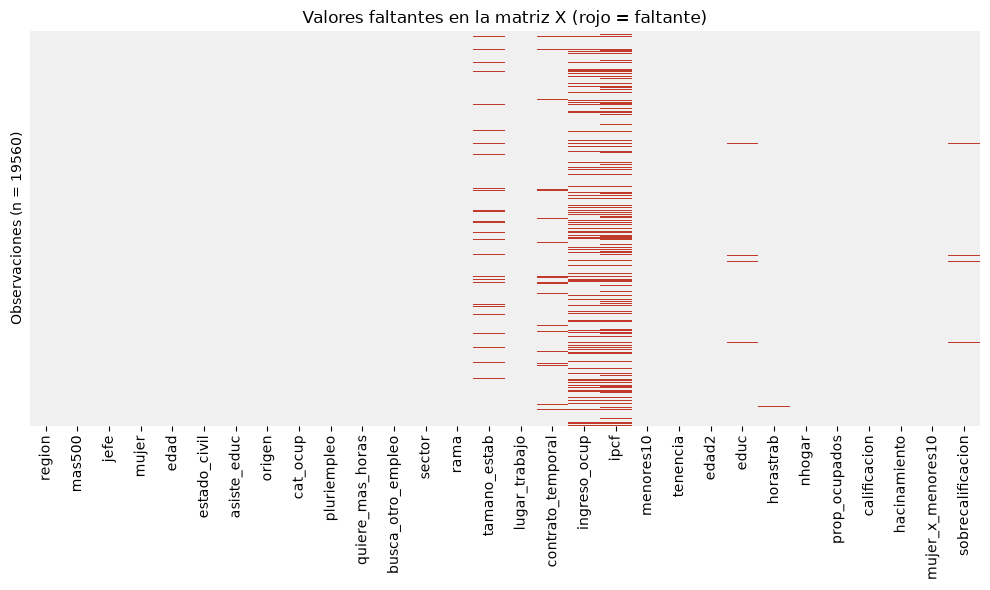

In [23]:
# X = todas las columnas menos los identificadores y la variable dependiente
X_diag = base.drop(columns=["CODUSU", "NRO_HOGAR", "COMPONENTE", "informal"])

os.makedirs("figuras", exist_ok=True)    # crea TP1/figuras si no existe

fig, ax = plt.subplots(figsize=(10, 6))
# X_diag.isna() es una tabla de True/False; el heatmap pinta True (faltante) en rojo
sns.heatmap(X_diag.isna(), cbar=False, yticklabels=False,
            cmap=["#f0f0f0", "#c0392b"], ax=ax)
ax.set_title("Valores faltantes en la matriz X (rojo = faltante)")
ax.set_ylabel(f"Observaciones (n = {len(X_diag)})")
plt.tight_layout()
plt.savefig("figuras/heatmap_faltantes.png", dpi=200, bbox_inches="tight")
plt.show()

In [24]:
porc = X_diag.isna().mean().mul(100).round(2).sort_values(ascending=False)
print("% de faltantes por variable:\n", porc[porc > 0])

grandes = ["ipcf", "ingreso_ocup", "tamano_estab", "contrato_temporal"]
print("\nFilas con algún NaN:", X_diag.isna().any(axis=1).sum())
print("Filas con NaN en otras variables (fuera de las 4 grandes):",
      X_diag.drop(columns=grandes).isna().any(axis=1).sum())
print("¿Todo NaN de ingreso_ocup es también NaN de ipcf?",
      (X_diag["ingreso_ocup"].isna() & X_diag["ipcf"].notna()).sum() == 0)

% de faltantes por variable:
 ipcf                 28.94
ingreso_ocup         19.01
tamano_estab          6.51
contrato_temporal     4.90
sobrecalificacion     1.40
educ                  1.31
busca_otro_empleo     0.27
horastrab             0.21
calificacion          0.10
quiere_mas_horas      0.03
tenencia              0.03
hacinamiento          0.03
origen                0.01
dtype: float64

Filas con algún NaN: 7060
Filas con NaN en otras variables (fuera de las 4 grandes): 365
¿Todo NaN de ingreso_ocup es también NaN de ipcf? True


#### 3.2 Tratamiento de faltantes
Criterio según el tipo de variable:
1. Dummies y categóricas con pocos faltantes (busca_otro_empleo, quiere_mas_horas, calificacion,
   tenencia, origen): se elimina la fila (78 filas, 0,4%).
2. Categóricas con muchos faltantes: la no respuesta pasa a ser una categoría (tamano_estab = "ns_nr")
   o una dummy (contrato_nsnr). Eliminarlas costaría 2.144 filas con 57,5% de informales, y entre
   quienes no saben si su contrato termina el 89,7% es informal: se perdería una señal fuerte.
3. Continuas (ingreso_ocup, ipcf, educ, horastrab, hacinamiento): mediana de la base de entrenamiento,
   imputada en el inciso 4 después de partir la muestra. Para los ingresos se agregan además dummies
   de no declaración (ingreso_nr, ipcf_nr), porque su no respuesta es grande (19% y 29%).
4. sobrecalificacion se recalcula en el inciso 4 a partir de la educación imputada.

In [25]:
# Sólo las dummies/categóricas con pocos faltantes provocan la eliminación de la fila
cat_chicas = ["busca_otro_empleo", "quiere_mas_horas", "calificacion", "tenencia", "origen"]

antes = len(base)
base = base.dropna(subset=cat_chicas).copy()
print(f"Filas: {antes} -> {len(base)} (se eliminan {antes - len(base)})")

Filas: 19560 -> 19482 (se eliminan 78)


In [26]:
base["tamano_estab"] = base["tamano_estab"].fillna("ns_nr")      # fillna reemplaza NaN por un valor

# Primero se crea la dummy (mientras el NaN todavía existe) y después se rellena con 0
base["contrato_nsnr"] = base["contrato_temporal"].isna().astype(int)
base["contrato_temporal"] = base["contrato_temporal"].fillna(0)

base["ingreso_nr"] = base["ingreso_ocup"].isna().astype(int)
base["ipcf_nr"] = base["ipcf"].isna().astype(int)

print(base[["contrato_nsnr", "ingreso_nr", "ipcf_nr"]].sum())
print("\nNaN que quedan (se imputan en el inciso 4):")
print(base.isna().sum()[lambda s: s > 0])

contrato_nsnr     950
ingreso_nr       3690
ipcf_nr          5626
dtype: int64

NaN que quedan (se imputan en el inciso 4):
ingreso_ocup         3690
ipcf                 5626
educ                  255
horastrab              37
sobrecalificacion     255
dtype: int64


#### 3.3 Variables categóricas → dummies
Cada categoría pasa a ser una columna 0/1, excepto una categoría de referencia por variable.
La referencia se omite porque las dummies de una misma variable suman 1 en cada fila, igual que la
columna de unos del intercepto: con todas incluidas habría colinealidad perfecta. El coeficiente de
cada dummy se interpreta en comparación con la referencia. Elegimos como referencia la categoría
más frecuente o la más natural para comparar.

In [27]:
no_predictoras = ["CODUSU", "NRO_HOGAR", "COMPONENTE", "informal"]
referencias = {"region": "GBA", "estado_civil": "soltero", "origen": "misma_prov",
               "cat_ocup": "asalariado", "sector": "privado", "rama": "comercio",
               "tamano_estab": "mas_de_40", "lugar_trabajo": "local",
               "tenencia": "propietario", "calificacion": "operativa"}

# pd.Categorical fija el orden de las categorías poniendo la referencia primero;
# get_dummies con drop_first=True elimina justamente esa primera.
for var, ref in referencias.items():
    otras = sorted(c for c in base[var].unique() if c != ref)
    base[var] = pd.Categorical(base[var], categories=[ref] + otras)

datos = pd.get_dummies(base, columns=list(referencias), drop_first=True, dtype=int)
X_cols = [c for c in datos.columns if c not in no_predictoras]
print("Dimensión de datos:", datos.shape, "| Columnas de X:", len(X_cols))

Dimensión de datos: (19482, 70) | Columnas de X: 66


#### 3.4 Tabla de diferencia de medias
Para cada variable de X: media entre formales, media entre informales, diferencia (informales − formales)
y p-valor del test t. H0: las medias poblacionales de ambos grupos son iguales.
Se usa la versión de Welch (equal_var=False), que no supone igual varianza en los dos grupos.
Para las dummies, la media es la proporción del grupo que tiene esa característica.
Las medias de los ingresos se calculan sólo con quienes los declararon (nan_policy="omit").
La tabla se guarda como .tex.

In [28]:
informales = datos[datos["informal"] == 1]
formales = datos[datos["informal"] == 0]

filas = []
for v in X_cols:
    t, p = stats.ttest_ind(informales[v], formales[v], equal_var=False, nan_policy="omit")
    filas.append({"variable": v,
                  "formales": formales[v].mean(),
                  "informales": informales[v].mean(),
                  "diferencia": informales[v].mean() - formales[v].mean(),
                  "p_valor": p})
tabla_medias = pd.DataFrame(filas).set_index("variable")

pd.set_option("display.max_rows", 100)      # mostrar las 66 filas
print(tabla_medias.round(3))
print("\nNo significativas al 5%:", list(tabla_medias.index[tabla_medias["p_valor"] > 0.05]))

                                    formales  informales  diferencia  p_valor
variable                                                                     
mas500                                 0.465       0.508       0.043    0.000
jefe                                   0.548       0.415      -0.133    0.000
mujer                                  0.448       0.460       0.012    0.086
edad                                  43.490      39.419      -4.071    0.000
asiste_educ                            0.053       0.090       0.037    0.000
pluriempleo                            0.088       0.086      -0.002    0.708
quiere_mas_horas                       0.086       0.263       0.177    0.000
busca_otro_empleo                      0.085       0.256       0.171    0.000
contrato_temporal                      0.022       0.120       0.097    0.000
ingreso_ocup                     1311516.902  551974.579 -759542.323    0.000
ipcf                             1046680.104  562131.989 -484548

In [29]:
def formato(x, dec=3):
    """Número con coma decimal y punto de miles; el signo menos, en modo matemático."""
    s = f"{abs(x):,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")
    return f"$-${s}" if x < 0 else s

def formato_p(p):
    return "$<$0,001" if p < 0.001 else formato(p, 3)

def tabla_a_latex(tabla, archivo, n_formales, n_informales, variables=None,
                  en_miles=("ingreso_ocup", "ipcf")):
    """Escribe la tabla como longtable de LaTeX (puede ocupar más de una página).
    variables: lista opcional para exportar sólo algunas filas."""
    t = tabla if variables is None else tabla.loc[variables]
    lineas = [r"\begin{longtable}{lrrrr}",
              r"\caption{Diferencia de medias entre ocupados formales e informales}\label{tab:medias}\\",
              r"\toprule",
              r"Variable & Formales & Informales & Diferencia & $p$-valor \\",
              rf" & ($n={formato(n_formales, 0)}$) & ($n={formato(n_informales, 0)}$) & (I $-$ F) & \\",
              r"\midrule", r"\endfirsthead",
              r"\toprule Variable & Formales & Informales & Diferencia & $p$-valor \\ \midrule",
              r"\endhead", r"\bottomrule", r"\endlastfoot"]
    for var, fila in t.iterrows():
        escala, dec = (1000, 1) if var in en_miles else (1, 3)
        nombre = var.replace("_", r"\_") + (r" (miles de \$)" if var in en_miles else "")
        lineas.append(f"{nombre} & {formato(fila['formales'] / escala, dec)} & "
                      f"{formato(fila['informales'] / escala, dec)} & "
                      f"{formato(fila['diferencia'] / escala, dec)} & {formato_p(fila['p_valor'])} \\\\")
    lineas.append(r"\end{longtable}")
    with open(archivo, "w", encoding="utf-8") as f:
        f.write("\n".join(lineas))

os.makedirs("tablas", exist_ok=True)
tabla_a_latex(tabla_medias, "tablas/diferencia_medias.tex",
              n_formales=len(formales), n_informales=len(informales))
print("Guardada en tablas/diferencia_medias.tex")

Guardada en tablas/diferencia_medias.tex


#### 3.5 Tabla reducida para el informe
La tabla completa (66 filas) ocupa dos páginas. Para el informe exportamos una selección de
25 variables con nombres legibles, como `tabular` simple: el título y el tamaño se controlan
desde el documento LaTeX.

In [30]:
# Diccionario {nombre en el notebook: etiqueta para el informe}. El orden del diccionario es el orden de las filas.
etiquetas = {
    "edad": "Edad (años)", "educ": "Educación (años)", "horastrab": "Horas trabajadas (semana)",
    "nhogar": "Miembros del hogar", "hacinamiento": "Hacinamiento (personas por ambiente)",
    "prop_ocupados": "Proporción de ocupados del hogar",
    "ingreso_ocup": "Ingreso ocupación principal (miles de \\$)",
    "ipcf": "Ingreso per cápita familiar (miles de \\$)",
    "mujer": "Mujer", "mujer_x_menores10": "Mujer $\\times$ menores de 10",
    "jefe": "Jefe/a de hogar", "cat_ocup_cuenta_propia": "Cuenta propia",
    "sector_estatal": "Sector estatal", "tamano_estab_hasta_5": "Establecimiento de hasta 5 personas",
    "contrato_temporal": "Contrato con fecha de finalización", "contrato_nsnr": "Contrato: no sabe/no responde",
    "quiere_mas_horas": "Quiere trabajar más horas",
    "lugar_trabajo_domicilio_cliente": "Trabaja en domicilio del cliente",
    "rama_construccion": "Rama: construcción", "rama_servicio_domestico": "Rama: servicio doméstico",
    "calificacion_profesional": "Calificación: profesional", "calificacion_no_calificada": "Calificación: no calificada",
    "sobrecalificacion": "Sobrecalificación", "ingreso_nr": "No declara ingreso de la ocupación",
    "region_Patagonia": "Región Patagonia"}

def tabla_reducida_latex(tabla, etiquetas, archivo, en_miles=("ingreso_ocup", "ipcf")):
    """Escribe sólo las filas de 'etiquetas', como tabular (sin entorno table)."""
    lineas = [r"\begin{tabular}{lrrrr}", r"\toprule",
              r"Variable & Formales & Informales & Diferencia & $p$-valor \\", r"\midrule"]
    for var, nombre in etiquetas.items():
        fila = tabla.loc[var]
        escala, dec = (1000, 1) if var in en_miles else (1, 3)
        lineas.append(f"{nombre} & {formato(fila['formales'] / escala, dec)} & "
                      f"{formato(fila['informales'] / escala, dec)} & "
                      f"{formato(fila['diferencia'] / escala, dec)} & {formato_p(fila['p_valor'])} \\\\")
    lineas += [r"\bottomrule", r"\end{tabular}"]
    with open(archivo, "w", encoding="utf-8") as f:
        f.write("\n".join(lineas))

tabla_reducida_latex(tabla_medias, etiquetas, "tablas/diferencia_medias_reducida.tex")
print("Guardada en tablas/diferencia_medias_reducida.tex con", len(etiquetas), "filas")

Guardada en tablas/diferencia_medias_reducida.tex con 25 filas


### Inciso 4
Partimos la muestra en entrenamiento (70%) y test (30%) con semilla 444, sin estratificar
(la consigna no lo pide y las clases están casi balanceadas). Después:
- Imputamos las variables continuas con la mediana de ENTRENAMIENTO, en las dos bases.
- Recalculamos sobrecalificacion donde faltaba (dependía de la educación faltante).
- Agregamos la columna de unos para el intercepto.
- Guardamos la base limpia.

#### 4.1 División de la base
Partimos la muestra en entrenamiento (70%) y test (30%) con semilla 444, sin estratificar
(la consigna no lo pide y las clases están casi balanceadas).

In [31]:
y = datos["informal"]
X = datos[X_cols]

# train_size=0.7: 70% para entrenamiento. random_state=444: fija el azar de la partición,
# así cualquiera que corra el código obtiene exactamente las mismas personas en cada parte.
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, random_state=444)

print("Entrenamiento:", X_train.shape, "| Test:", X_test.shape)
print(f"Informales en entrenamiento: {y_train.mean():.2%} | en test: {y_test.mean():.2%}")

Entrenamiento: (13637, 66) | Test: (5845, 66)
Informales en entrenamiento: 44.73% | en test: 45.46%


#### 4.2 Imputación de medianas
Imputamos las variables continuas con la mediana de ENTRENAMIENTO, en los valores faltantes de ambas bases.

In [32]:
continuas_nan = ["ingreso_ocup", "ipcf", "educ", "horastrab", "hacinamiento"]

# Las medianas se calculan SÓLO con entrenamiento...
medianas = X_train[continuas_nan].median()
print("Medianas de entrenamiento:\n", medianas)

# ...y se usan para completar las DOS bases. El test se completa con la mediana de entrenamiento
# (no con la propia), igual que se completaría el dato de una persona nueva.
# fillna con una Serie completa cada columna con el valor que le corresponde por nombre.
X_train = X_train.fillna(medianas)
X_test = X_test.fillna(medianas)

Medianas de entrenamiento:
 ingreso_ocup    800000.0
ipcf            600000.0
educ                12.0
horastrab           40.0
hacinamiento         1.0
dtype: float64


#### 4.3 Sobrecalificación
Recalculamos sobrecalificacion donde faltaba (dependía de la educación faltante).

In [33]:
def recalcular_sobrecalificacion(Z):
    """Completa sobrecalificacion donde faltaba, usando la educación ya imputada.
    'Operativa' es la categoría de referencia: no tiene dummy propia, así que se reconoce
    porque las otras tres dummies de calificación valen 0."""
    operativa = ((Z["calificacion_profesional"] == 0) & (Z["calificacion_tecnica"] == 0)
                 & (Z["calificacion_no_calificada"] == 0))
    puesto_bajo = operativa | (Z["calificacion_no_calificada"] == 1)
    falta = Z["sobrecalificacion"].isna()
    Z.loc[falta, "sobrecalificacion"] = ((Z.loc[falta, "educ"] >= 15) & puesto_bajo[falta]).astype(float)
    return falta.sum()

print("sobrecalificacion recalculada en", recalcular_sobrecalificacion(X_train),
      "filas de entrenamiento y", recalcular_sobrecalificacion(X_test), "de test")
print("NaN que quedan:", X_train.isna().sum().sum(), "en entrenamiento,",
      X_test.isna().sum().sum(), "en test")

sobrecalificacion recalculada en 173 filas de entrenamiento y 82 de test
NaN que quedan: 0 en entrenamiento, 0 en test


#### 4.4 Intercepto
Agregamos la columna de unos para el intercepto.

In [34]:
# add_constant agrega una columna "const" llena de unos al principio de X.
# has_constant="add" la agrega aunque statsmodels crea que ya hay una columna constante.
X_train = sm.add_constant(X_train)
X_test = sm.add_constant(X_test, has_constant="add")
print(X_train.shape, X_test.shape)
print(X_train.columns[:3].tolist())

(13637, 67) (5845, 67)
['const', 'mas500', 'jefe']


#### 4.5 Base limpia
Guardamos una sola base con: identificadores (para volver a unir con la EPH si hace falta),
una columna `muestra` que indica si cada fila está en entrenamiento o en test, la variable
dependiente y X ya imputada (sin la constante, que se agrega en una línea).
Con la columna `muestra`, en los TP2 y TP3 se recupera exactamente esta partición sin volver a
correr la limpieza.

In [35]:
# Unimos entrenamiento y test, marcando de dónde viene cada fila
base_limpia = pd.concat([X_train, X_test]).drop(columns="const")
base_limpia.insert(0, "informal", pd.concat([y_train, y_test]))
base_limpia.insert(0, "muestra", ["train"] * len(X_train) + ["test"] * len(X_test))

# join pega los identificadores usando el índice (el número de fila original)
base_limpia = datos[["CODUSU", "NRO_HOGAR", "COMPONENTE"]].join(base_limpia, how="inner").sort_index()

base_limpia.to_csv("data/base_limpia_TP1.csv", index=False, encoding="utf-8")
print(base_limpia.shape, base_limpia["muestra"].value_counts().to_dict())
print("NaN en la base limpia:", base_limpia.isna().sum().sum())

(19482, 71) {'train': 13637, 'test': 5845}
NaN en la base limpia: 0
